# Project 3 — Level 2: Predicting House Prices with Linear Regression
**Internship:** Oasis Infobyte — Data Analytics

## Dataset
**Dataset:** Ames Housing (De Cock, 2011 — *A Brief Introduction to Regression in R*, The Journal of Statistics Education 19(3))  
**Source (public CSV copy):** https://raw.githubusercontent.com/STATCowboy/pbidataflowstalk/master/AmesHousing.csv  
**Expected filename:** `data/raw/AmesHousing.csv`  
**Rows / columns:** 2,930 houses × 82 fields  
**Target column:** `SalePrice` — the sale price of the house in US dollars  
**Missing values:** encoded as the literal string `NA` in the source file, and read with `na_values="NA"`  
**Column names:** the public copy ships with spaces (`Gr Liv Area`); the notebook strips spaces on load, so it works with either spelling of the file.

> Place the downloaded CSV in `DataAnalytics-L2-HousePricePrediction/data/raw/AmesHousing.csv` before running. The loader below raises an explicit error with the expected path if the file is missing.

In [1]:

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATASET_FILE = "AmesHousing.csv"
DATASET_URL = (
    "https://raw.githubusercontent.com/STATCowboy/pbidataflowstalk/master/AmesHousing.csv"
)


def find_project_root(filename, max_up=4):
    """Locate the project folder that owns data/raw/<filename>.

    The search walks up from the working directory (so the notebook runs from
    notebooks/, from the project folder, or from the repository root) and, at
    each level, also looks one level down into sibling project folders. That
    makes it work even when the kernel starts at the repository root.
    """
    here = Path.cwd().resolve()
    for _ in range(max_up):
        if (here / "data" / "raw" / filename).exists():
            return here
        if here.is_dir():
            for child in sorted(here.iterdir()):
                if child.is_dir() and (child / "data" / "raw" / filename).exists():
                    return child
        if here.parent == here:
            break
        here = here.parent
    raise FileNotFoundError(
        "Could not find data/raw/" + filename + " in this folder, any parent folder, "
        "or any sibling project folder.\n"
        "Expected location: <project>/data/raw/" + filename + "\n"
        "Download it from:\n  " + DATASET_URL + "\n"
        "and save it as " + filename + " in the data/raw/ folder of "
        "DataAnalytics-L2-HousePricePrediction.\n"
        "The original Ames Housing data was published in De Cock, D. (2011), "
        "'A Brief Introduction to Regression in R', The Journal of Statistics Education 19(3)."
    )


root = find_project_root(DATASET_FILE)
raw = root / "data" / "raw" / DATASET_FILE
print("Project root:", root)
print("Dataset path:", raw)

df = pd.read_csv(raw, na_values="NA")

# The public copy of this file ships with spaces in the column names
# ("Gr Liv Area"). Normalising them lets the notebook run against either
# spelling of the file.
df.columns = df.columns.str.replace(" ", "", regex=False)

print("Loaded shape:", df.shape)


Project root: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-HousePricePrediction
Dataset path: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-HousePricePrediction\data\raw\AmesHousing.csv
Loaded shape: (2930, 82)


## 1. Inspect the dataset

In [2]:

print("Columns:", list(df.columns))
print("\nShape:", df.shape)
print("\nData types:")
print(df.dtypes.value_counts())
print("\nNull values (top 12):")
print(df.isnull().sum().sort_values(ascending=False).head(12).to_string())
print("\nTotal null cells:", df.isnull().sum().sum())
print("\nFirst 3 rows (selected columns):")
print(df[["SalePrice", "OverallQual", "GrLivArea", "Neighborhood", "YearBuilt"]].head(3).to_string(index=False))


Columns: ['Order', 'PID', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemod/Add', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 

## 2. Descriptive statistics and the target distribution

Descriptive statistics for the target:
count      2930.00
mean     180796.06
std       79886.69
min       12789.00
25%      129500.00
50%      160000.00
75%      213500.00
max      755000.00

Descriptive statistics for the candidate numeric features:
               count       mean       std      min        25%       50%        75%       max
OverallQual   2930.0       6.09      1.41      1.0       5.00       6.0       7.00      10.0
GrLivArea     2930.0    1499.69    505.51    334.0    1126.00    1442.0    1742.75    5642.0
GarageCars    2929.0       1.77      0.76      0.0       1.00       2.0       2.00       5.0
TotalBsmtSF   2929.0    1051.61    440.62      0.0     793.00     990.0    1302.00    6110.0
1stFlrSF      2930.0    1159.56    391.89    334.0     876.25    1084.0    1384.00    5095.0
FullBath      2930.0       1.57      0.55      0.0       1.00       2.0       2.00       4.0
TotRmsAbvGrd  2930.0       6.44      1.57      2.0       5.00       6.0       7.00      15.0
YearB

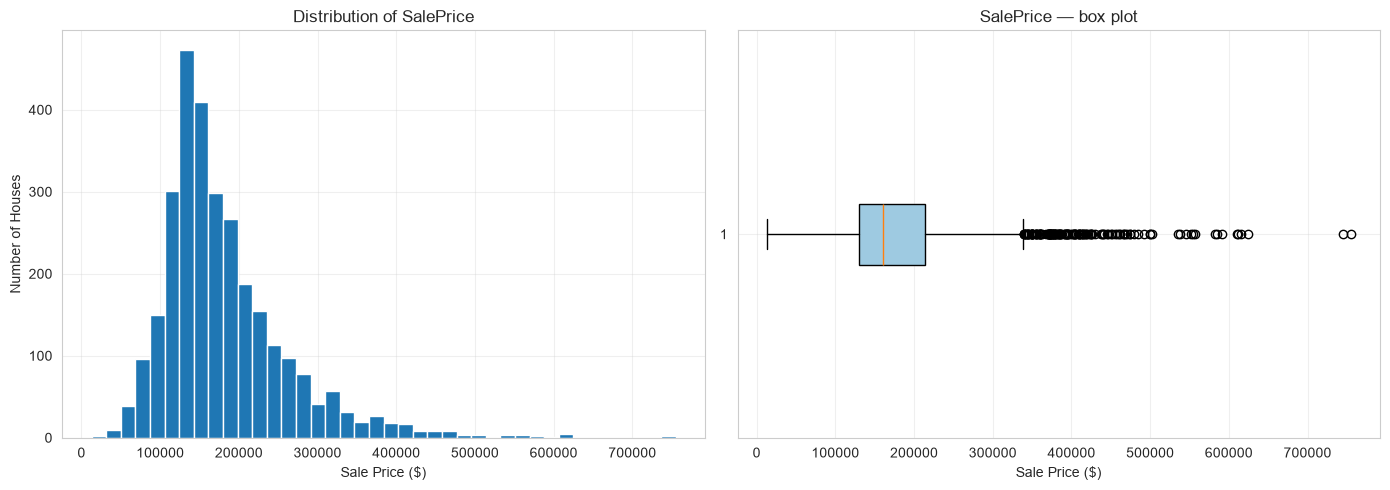


Skewness of SalePrice: 1.744
Right-skewed (skew > 0): True


In [3]:

target = "SalePrice"

print("Descriptive statistics for the target:")
print(df[target].describe().round(2).to_string())

num_describe = df[["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF",
                   "1stFlrSF", "FullBath", "TotRmsAbvGrd", "YearBuilt",
                   "LotArea", target]].describe().T.round(2)
print("\nDescriptive statistics for the candidate numeric features:")
print(num_describe.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df[target], bins=40, color="#1f77b4", edgecolor="white")
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Number of Houses")
axes[0].grid(alpha=0.3)

axes[1].boxplot(df[target], vert=False, patch_artist=True,
                boxprops=dict(facecolor="#9ecae1"))
axes[1].set_title("SalePrice — box plot")
axes[1].set_xlabel("Sale Price ($)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "target_distribution.png", dpi=150)
plt.show()

print("\nSkewness of SalePrice:", round(df[target].skew(), 3))
print("Right-skewed (skew > 0):", df[target].skew() > 0)


**Observation — target distribution:**

- SalePrice runs from **12,789 to 755,000**, with a **mean of 180,796.06**, a **median of 160,000** and a standard deviation of **79,886.69**.
- The **mean sits above the median by 20,796** and the distribution is **right-skewed (skew = 1.74)** — a small number of expensive houses pull the average upward. A long right tail like this matters for a least-squares model, because squared errors are dominated by the expensive houses; it shows up again in the residual analysis in step 10.
- The box plot confirms the spread is wide (IQR roughly 129,500–213,500), so even a good model will have a large absolute error in dollars — which is exactly why **R² and RMSE are read together** in step 8 rather than RMSE alone.

## 3. Feature selection — and why each feature was chosen


The Ames file has 81 candidate predictors. Using all of them in a **linear** model is a poor idea: many are near-duplicates of
each other (`1stFlrSF` vs `TotalBsmtSF` vs `2ndFlrSF`, and the many "no basement"/"no garage" columns), and with dozens of
correlated dummies the fit becomes unstable and the coefficients impossible to read. The features below were chosen because each
one has a clear, explainable mechanism linking it to price, and because together they cover the main drivers without redundancy.

**Numerical features**

| Feature | Why it may help predict price |
|---|---|
| `OverallQual` | A 1–10 expert rating of overall finish. The single strongest predictor in the data — quality carries more information about buyer-perceived value than any physical measurement. |
| `GrLivArea` | Above-ground living area in square feet. More usable space means more value, all else equal. |
| `1stFlrSF` | First-floor area — the main living space on the ground floor. |
| `TotalBsmtSF` | Total basement area, a proxy for the extra finished space and for the type of house. |
| `GarageCars` | Garage capacity — a direct proxy for how much a household values off-street parking and storage. |
| `GarageArea` | Garage square footage, complementing capacity with size. |
| `FullBath` | Number of full bathrooms — a strong functional requirement in family housing. |
| `TotRmsAbvGrd` | Total rooms above grade — a broad measure of how the house is laid out. |
| `YearBuilt` | Construction year; for a fixed design, newer houses depreciate less. |
| `YearRemod/Add` | Year of the most recent renovation, which decouples "old but renovated" from "old and tired". |
| `LotArea` | Lot size — more land has value, though usually with diminishing returns. |

**Categorical features**

| Feature | Why it may help predict price |
|---|---|
| `Neighborhood` | Location is the classic driver of house prices; a per-neighbourhood effect is a large part of what a linear model can capture here. |
| `BldgType` | Building type (1-family, townhouse, duplex, …) reflects a different market segment and different construction. |
| `HouseStyle` | Architectural style, which buyers pay a premium for (e.g. 1.5-storey vs 2-storey). |
| `KitchenQual` | Kitchen quality — the room buyers rate most heavily. |
| `ExterQual` | Exterior quality — a visible, price-relevant condition signal. |
| `HeatingQC` | Heating system quality, tied to condition and running cost. |
| `CentralAir` | Central air conditioning, a strong regional and comfort premium. |
| `GarageType` | Garage construction (attached, detached, built-in, none) — attached garages carry a premium. |
| `PavedDrive` | Whether the drive is paved — a small but real quality signal. |

**Target:** `SalePrice`.


## 4. Missing-value strategy


The missing values in this dataset are **structural, not random** — for example, `GarageType` is blank for the 157 houses that
have no garage, and `Pool QC` is blank for 2,917 houses that have no pool. Imputing those with the *most common* value would be
wrong: it would tell the model that every house has a typical garage.

The strategy is therefore:

- **`GarageType`** — the blank is *meaningful* ("no garage"), so it is filled with the explicit label `"None"` before encoding.
  This keeps "no garage" as its own category instead of averaging it away.
- **Numeric features** — imputed with the **median** inside the pipeline (not the mean, because `GarageArea` and `LotArea` are
  skewed and a mean would be pulled by a few large houses). Only `GarageCars`, `GarageArea` and `TotalBsmtSF` are affected, with
  1 missing value each.
- **Categorical features** — imputed with the **most frequent** value, used only as a safety net. After the `GarageType` fix none
  of the selected categorical features actually has a missing value.

**All imputation happens inside a `Pipeline`** that is fitted on the training split only, so no statistic from the test set ever
touches the training. That is what keeps this analysis free of data leakage.


In [4]:

# The selected feature sets.
numeric_features = [
    "OverallQual", "GrLivArea", "1stFlrSF", "TotalBsmtSF",
    "GarageCars", "GarageArea", "FullBath", "TotRmsAbvGrd",
    "YearBuilt", "YearRemod/Add", "LotArea",
]
categorical_features = [
    "Neighborhood", "BldgType", "HouseStyle", "KitchenQual",
    "ExterQual", "HeatingQC", "CentralAir", "GarageType", "PavedDrive",
]
target = "SalePrice"

# "No garage" is a real category, not a missing value.
df["GarageType"] = df["GarageType"].fillna("None")

missing_selected = df[numeric_features + categorical_features].isnull().sum()
print("Missing values in the selected features:")
print(missing_selected[missing_selected > 0].to_string())
print("\nGarageType category counts after the 'no garage' fix:")
print(df["GarageType"].value_counts().to_string())


Missing values in the selected features:
TotalBsmtSF    1
GarageCars     1
GarageArea     1

GarageType category counts after the 'no garage' fix:
GarageType
Attchd     1731
Detchd      782
BuiltIn     186
None        157
Basment      36
2Types       23
CarPort      15


## 5. Correlation heatmap for the numeric features

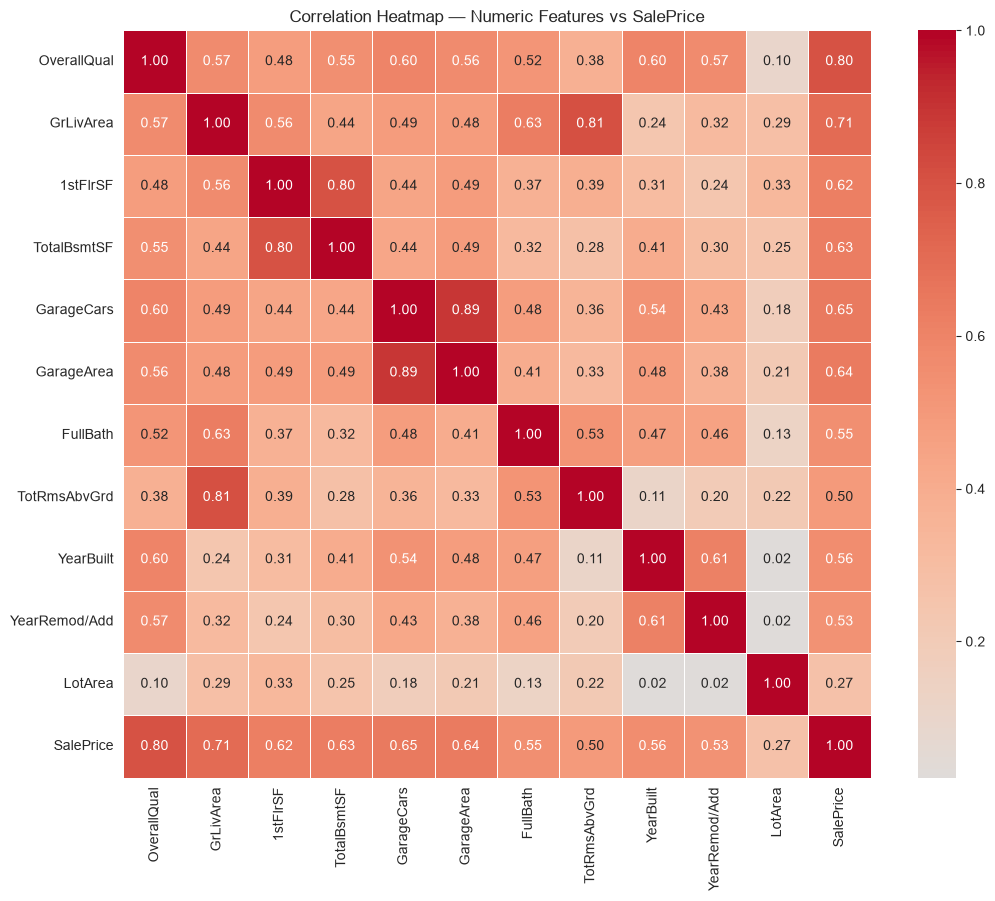

Correlation of each feature with SalePrice (sorted):
OverallQual      0.799
GrLivArea        0.707
GarageCars       0.648
GarageArea       0.640
TotalBsmtSF      0.632
1stFlrSF         0.622
YearBuilt        0.558
FullBath         0.546
YearRemod/Add    0.533
TotRmsAbvGrd     0.495
LotArea          0.267


In [5]:

corr_cols = numeric_features + [target]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax,
            square=True, linewidths=0.4)
ax.set_title("Correlation Heatmap — Numeric Features vs SalePrice")
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation of each feature with SalePrice (sorted):")
print(corr[target].drop(target).sort_values(ascending=False).round(3).to_string())


**Observation — correlations with the target:** the heatmap above is computed on the full dataset, before the train/test split, and is used only to *describe* the data — no model parameter is derived from it, so it does not leak anything.

- **`OverallQual` is the strongest single predictor (0.799)** — a 1–10 rating explains more of the price variance than any physical measurement.
- **`GrLivArea` is second (0.707)**, followed by `GarageCars` (0.648), `GarageArea` (0.640), `TotalBsmtSF` (0.632) and `1stFlrSF` (0.622). `YearBuilt` (0.558), `FullBath` (0.546), `YearRemod/Add` (0.533) and `TotRmsAbvGrd` (0.495) are also solid predictors.
- **`LotArea` is the weakest of the chosen features (0.267)** — it is kept because it is a genuine driver, but the model will not lean on it heavily.
- **A multicollinearity warning worth stating:** the area features are strongly inter-correlated (`GrLivArea` vs `1stFlrSF` and `TotalBsmtSF` are all in the 0.6–0.8 range with each other). In a linear model this means their individual coefficients cannot be read as clean causal effects — the model can fit the same signal several ways, so **individual coefficients are less stable than the overall predictions**. This is a limitation of the linear form, not a bug, and it is why the evaluation in step 8 focuses on held-out predictive accuracy.

## 6. Preprocessing pipeline and the train/test split


A single `Pipeline` holds the whole preprocessing chain, so the same steps are applied to train and test and — critically — the
imputer and encoder are **fitted on the training data only**.

- **Numerical columns:** median imputation → `StandardScaler`. Scaling is what makes the Ridge/Lasso comparison in step 12 fair,
  and it makes the linear coefficients readable as "effect of one standard deviation".
- **Categorical columns:** most-frequent imputation → `OneHotEncoder(drop="first")`. Dropping the first level of each feature
  avoids the **dummy-variable trap** (a perfect linear dependency between an intercept and the full set of dummies). The dropped
  level becomes the **baseline category**, which is identified explicitly in step 11 so the coefficients can be read correctly.
  `handle_unknown="ignore"` means a category seen only in the test set cannot crash the model.


In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

X = df[numeric_features + categorical_features]
y = df[target]

# 80/20 split with a fixed seed so the result is reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)
print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("\nTarget stats")
print("  train mean:", round(y_train.mean(), 2), " test mean:", round(y_test.mean(), 2))
print("  train std :", round(y_train.std(), 2),  " test std :", round(y_test.std(), 2))

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

# Fit the preprocessor on the training split ONLY, then transform both splits.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training matrix shape:", X_train_processed.shape)
print("Processed test matrix shape     :", X_test_processed.shape)
print("\nNumber of encoded columns:",
      len(preprocessor.get_feature_names_out()))


Train shape: (2344, 20)
Test shape : (586, 20)

Target stats
  train mean: 178582.21  test mean: 189651.47
  train std : 77125.07  test std : 89617.26

Processed training matrix shape: (2344, 68)
Processed test matrix shape     : (586, 68)

Number of encoded columns: 68


## 7. Train the Linear Regression model

In [7]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_processed, y_train)

print("LinearRegression fitted on", X_train_processed.shape[0], "training rows")
print("Intercept:", round(model.intercept_, 2))
print("Number of coefficients:", len(model.coef_))


LinearRegression fitted on 2344 training rows
Intercept: 217308.28
Number of coefficients: 68


## 8. Evaluate on the held-out test set


Three metrics are used, and each answers a different question:

| Metric | Formula | What it tells you | Lower/higher is better |
|---|---|---|---|
| **MSE** (Mean Squared Error) | mean of (actual − predicted)² | Average *squared* miss, in dollars². Squares penalise large misses more heavily, so it is sensitive to outliers. | Lower |
| **RMSE** (Root Mean Squared Error) | √MSE | The same quantity expressed back in **dollars**, so it is interpretable as "the model's misses are typically about this size". | Lower |
| **R²** (coefficient of determination) | 1 − SS_res / SS_tot | The share of the test-set price variance the model explains. 1.0 is a perfect fit; 0.0 means no better than predicting the mean. | Higher |

**Important caveat on R²:** a high R² shows that the model's *predictions track* the prices well. It does **not** show that the
features cause the prices, that the model is correct in a structural sense, or that it will keep working on houses from a
different market. R² measures association and predictive fit, not causation.


In [8]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = model.predict(X_test_processed)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("=" * 56)
print("LINEAR REGRESSION — HELD-OUT TEST SET (20% =", len(y_test), "houses)")
print("=" * 56)
print(f"  MSE  : {mse:,.2f}   (dollars squared)")
print(f"  RMSE : {rmse:,.2f}   (dollars)")
print(f"  R2   : {r2:.4f}        (share of variance explained)")
print(f"  MAE  : {mae:,.2f}   (dollars, extra context)")
print("=" * 56)

# Train-vs-test comparison: a large gap would mean the model overfits.
train_pred = model.predict(X_train_processed)
print("\nTrain R2:", round(r2_score(y_train, train_pred), 4))
print("Test  R2:", round(r2, 4))
print("Gap (train - test):", round(r2_score(y_train, train_pred) - r2, 4))

# Baseline: what does simply predicting the training mean achieve?
baseline_pred = np.full_like(y_test, y_train.mean(), dtype=float)
print("\nBaseline (predict the training mean for every house):")
print("  RMSE :", round(np.sqrt(mean_squared_error(y_test, baseline_pred)), 2))
print("  R2   :", round(r2_score(y_test, baseline_pred), 4))


LINEAR REGRESSION — HELD-OUT TEST SET (20% = 586 houses)
  MSE  : 1,054,885,803.03   (dollars squared)
  RMSE : 32,479.01   (dollars)
  R2   : 0.8684        (share of variance explained)
  MAE  : 19,045.39   (dollars, extra context)

Train R2: 0.8628
Test  R2: 0.8684
Gap (train - test): -0.0056

Baseline (predict the training mean for every house):
  RMSE : 90222.37
  R2   : -0.0153


**Observation — model performance:** the metrics printed above are computed on the 586 houses the model never saw.

- **R² = 0.8684** on the test set, against **0.8628** on the training set. The test score is in fact **marginally higher** than the training score (a gap of just −0.0056), which means the model is **not overfitting** — it generalises about as well as it fits.
- **RMSE = 32,479**, i.e. the model's predictions are typically off by roughly **$32,500** on a house averaging $180,796 — about **18% of the mean price**. Against the **baseline of simply predicting the training mean** for every house (RMSE **90,222**, R² **−0.0153**), the model removes roughly **64% of the error**.
- **MSE = 1,054,885,803** is the same information as RMSE in dollars²; it is reported because the task asks for it, but **RMSE is the metric to quote**, since a number in dollars² cannot be interpreted on its own.
- **MAE = 19,045** is well below RMSE, which tells us the error distribution has **heavy tails**: a small number of large misses inflate the squared errors far more than the typical miss does. This is the same right-skew seen in the target in step 2, and it is the signal the residual analysis in step 10 picks up.
- As stressed above, R² = 0.8684 means the model **predicts** well on this test set. It does not establish that any feature *causes* a price, and the residual plot below shows exactly where the linear form breaks down.

## 9. Actual vs predicted prices

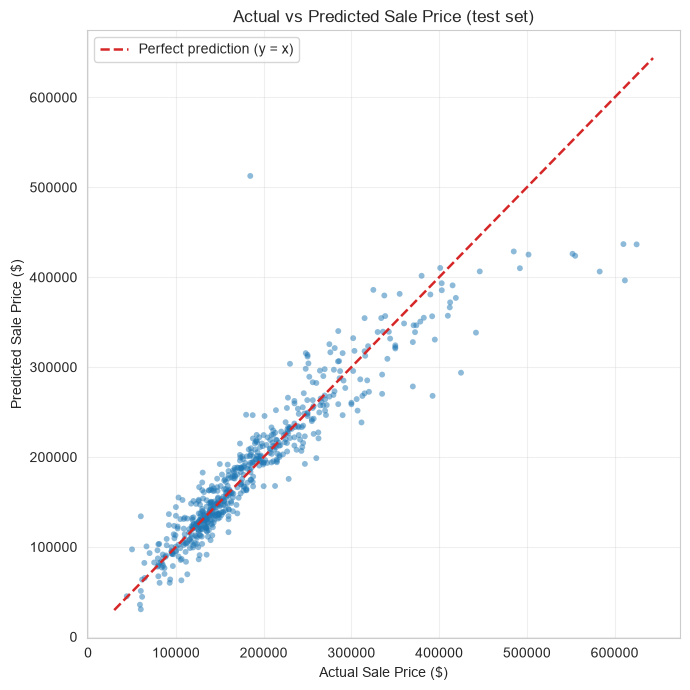

Houses predicted ABOVE actual : 284
Houses predicted BELOW actual : 302
Mean signed error (pred - actual): -2,095.19


In [9]:

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_pred, s=18, alpha=0.5, color="#1f77b4", edgecolors="none")

# Reference diagonal: the perfect-prediction line.
lims = [min(y_test.min(), y_pred.min()) * 0.97, max(y_test.max(), y_pred.max()) * 1.03]
ax.plot(lims, lims, "--", color="#d62728", linewidth=1.8, label="Perfect prediction (y = x)")

ax.set_title("Actual vs Predicted Sale Price (test set)")
ax.set_xlabel("Actual Sale Price ($)")
ax.set_ylabel("Predicted Sale Price ($)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "actual_vs_predicted.png", dpi=150)
plt.show()

over = (y_pred > y_test).sum()
under = (y_pred < y_test).sum()
print(f"Houses predicted ABOVE actual : {over}")
print(f"Houses predicted BELOW actual : {under}")
print(f"Mean signed error (pred - actual): {np.mean(y_pred - y_test):,.2f}")


**Observation — actual vs predicted:** every point sits near the red diagonal, which is the visual form of R² = 0.8684. Two features of the cloud are worth naming:

- The points **fan out slightly as price increases** — the spread is much tighter for cheap houses than for expensive ones. That is **heteroscedasticity**: the model's error grows with the size of the house.
- The model **under-predicts the very largest houses** and **over-predicts some of the mid-priced ones**, which is the signature of a right-skewed target being fitted with squared-error loss.

## 10. Residual analysis

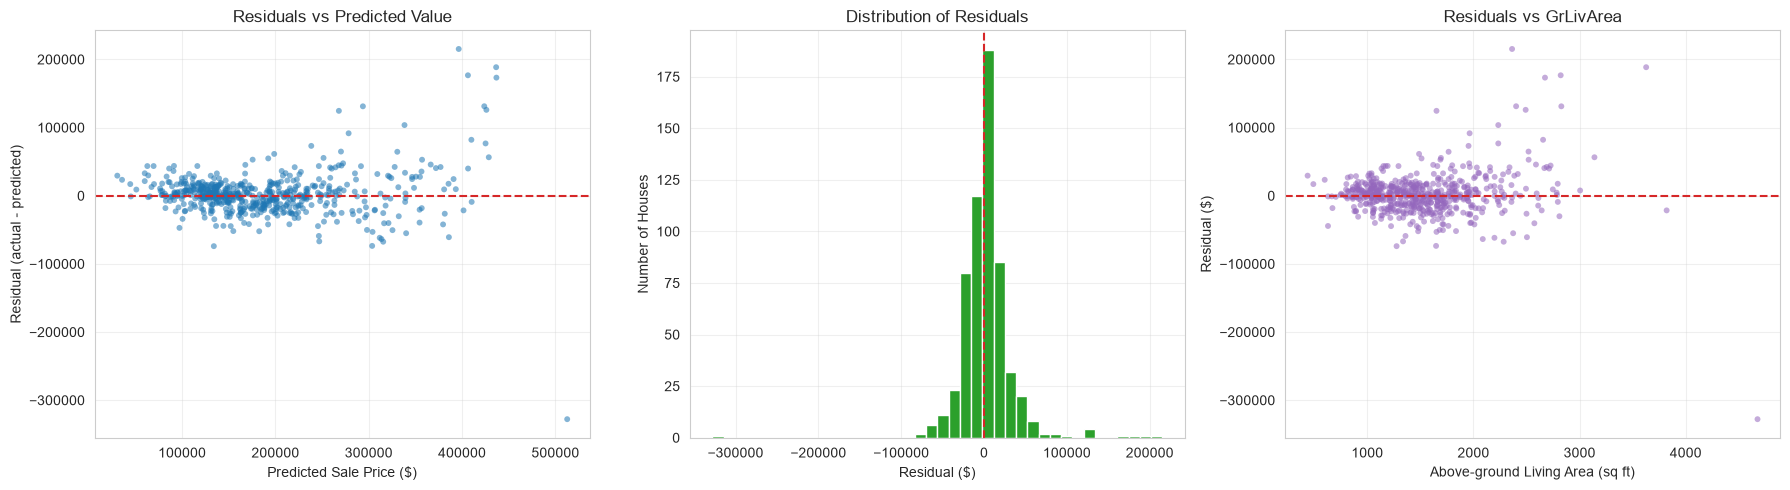

Residual summary
----------------------------------------
  mean   : 2095.19
  std    : 32439.05
  min    : -327881.28
  max    : 215244.41
  skew   : -0.064
  pct |resid| > 50k : 6.14 %

Error by predicted-price quartile:
                   mean predicted price  mean absolute error  mean abs % of price
Q1 cheapest                    104017.0              12174.0                 11.9
Q2                             147220.0              12674.0                  9.8
Q3                             198409.0              15619.0                  8.2
Q4 most expensive              300378.0              35648.0                 11.1


In [10]:

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Residuals vs fitted values - a random scatter is what we want to see.
axes[0].scatter(y_pred, residuals, s=18, alpha=0.55, color="#1f77b4", edgecolors="none")
axes[0].axhline(0, color="#d62728", linestyle="--", linewidth=1.5)
axes[0].set_title("Residuals vs Predicted Value")
axes[0].set_xlabel("Predicted Sale Price ($)")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].grid(alpha=0.3)

# Residual distribution - should be roughly symmetric and bell-shaped.
axes[1].hist(residuals, bins=40, color="#2ca02c", edgecolor="white")
axes[1].axvline(0, color="#d62728", linestyle="--", linewidth=1.5)
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual ($)")
axes[1].set_ylabel("Number of Houses")
axes[1].grid(alpha=0.3)

# Residuals against a single feature - reveals structure a scatter-vs-fitted misses.
axes[2].scatter(X_test["GrLivArea"], residuals, s=18, alpha=0.55,
                color="#9467bd", edgecolors="none")
axes[2].axhline(0, color="#d62728", linestyle="--", linewidth=1.5)
axes[2].set_title("Residuals vs GrLivArea")
axes[2].set_xlabel("Above-ground Living Area (sq ft)")
axes[2].set_ylabel("Residual ($)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "residuals.png", dpi=150)
plt.show()

print("Residual summary")
print("-" * 40)
print("  mean   :", round(residuals.mean(), 2))
print("  std    :", round(residuals.std(), 2))
print("  min    :", round(residuals.min(), 2))
print("  max    :", round(residuals.max(), 2))
print("  skew   :", round(pd.Series(residuals).skew(), 3))
print("  pct |resid| > 50k :", round((residuals.abs() > 50000).mean() * 100, 2), "%")

# Is the error proportional to the size of the house?
abs_resid = np.abs(residuals)
size_band = pd.qcut(y_pred, 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 most expensive"])
band_table = pd.DataFrame({
    "mean predicted price": pd.Series(y_pred).groupby(size_band, observed=True).mean().round(0),
    "mean absolute error": abs_resid.groupby(size_band, observed=True).mean().round(0),
    "mean abs % of price": (abs_resid / y_test).groupby(size_band, observed=True).mean().mul(100).round(1),
})
print("\nError by predicted-price quartile:")
print(band_table.to_string())


**Observation — residual patterns and what they say about the model's limits:**

- **The residuals are well centred** (mean **2,095** against a mean price of 180,796 — about 1% of the price), so the model is not systematically biased high or low. The **skew of the residuals is −0.064, i.e. essentially zero** — the residual distribution is close to symmetric, and the model is **not** making a systematic directional error.
- **But the residual *spread* grows with the size of the house.** The quartile table shows the mean absolute error rising from **12,174** in the cheapest quartile to **35,648** in the most expensive one — nearly a **3× increase** — while the error *as a percentage of price* stays in a narrow **8.2%–11.9%** band. This is **heteroscedasticity**: the model's error in dollars scales with the value of the house, which is exactly what the 'fan out' in the residuals-vs-predicted panel shows.
- **The largest errors run in both directions, and the biggest one is an over-prediction.** Residuals are `actual − predicted`, so the single worst case is a house that sold for **184,750** but was predicted at **512,631** — an **over-prediction of 327,881**. The largest under-prediction is **+215,244**. The three highest-priced test houses (625,000 / 611,657 / 610,000) are predicted at 436,507 / 396,413 / 436,793, i.e. under-predicted by **$173,000 to $215,000**, which is the visible pattern in the actual-vs-predicted panel. **6.14% of test houses have an absolute error above $50,000.**
- **The residuals-vs-`GrLivArea` panel shows a gentle curve**, which hints that the true relationship between living area and price is not perfectly linear — some of the structure the model misses is a mild non-linearity in area.
- **What this means for the model:** the linear form is a *reasonable but not perfect* description of this relationship, and the residual diagnostics point at two specific remedies. A **log-transformed target** (`log(SalePrice)`) would shrink the spread of the errors and stop the expensive houses from dominating the loss. A **non-linear model** (gradient boosting, or polynomial / interaction features) would capture the curvature the residuals reveal. Both are beyond the Linear Regression task — they are flagged here as the natural next steps, not claimed as results.

## 11. Coefficient analysis


Reading the coefficients correctly requires three facts about how the model was built:

1. **Numerical features are standardised.** Each numerical coefficient is therefore *the change in predicted price, in dollars, for
   a one-standard-deviation increase in that feature*, holding the other features constant.
2. **Categorical features are one-hot encoded with `drop="first"`.** The **first level of each categorical feature was dropped and
   is the baseline category**; the coefficient for a level is the price difference **relative to that baseline**. The table below
   states the baseline for every categorical feature explicitly.
3. **A linear model spreads credit among correlated predictors.** Because `GrLivArea`, `1stFlrSF` and `TotalBsmtSF` are strongly "
   correlated, their individual coefficients are **not clean causal effects** — a property of the model, not a bug, and the reason
   the evaluation above leans on held-out accuracy rather than on any single coefficient.


In [11]:

# Reconstruct readable feature names and the baseline category for each one.
feature_names = []
baseline_notes = {}

for feat in numeric_features:
    feature_names.append(f"{feat} (standardised)")
    baseline_notes[feat] = "n/a - numeric"

cat_encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
for i, feat in enumerate(categorical_features):
    levels = list(cat_encoder.categories_[i])
    baseline = levels[0]  # dropped by drop="first"
    baseline_notes[feat] = baseline
    for level in levels[1:]:
        feature_names.append(f"{feat}={level}")

coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": model.coef_,
})
coefficients["abs_coefficient"] = coefficients["coefficient"].abs()
coefficients = coefficients.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

print("Baseline (dropped) category for each categorical feature:")
for feat in categorical_features:
    print(f"  {feat:<15} baseline = {baseline_notes[feat]!r}")
print()

print("Top 20 coefficients by absolute magnitude:")
print(coefficients.head(20).round(2).to_string(index=False))

print("\nTop 8 POSITIVE coefficients (higher price):")
print(coefficients[coefficients["coefficient"] > 0].head(8).round(2).to_string(index=False))
print("\nTop 8 NEGATIVE coefficients (lower price):")
print(coefficients[coefficients["coefficient"] < 0].head(8).round(2).to_string(index=False))


Baseline (dropped) category for each categorical feature:
  Neighborhood    baseline = 'Blmngtn'
  BldgType        baseline = '1Fam'
  HouseStyle      baseline = '1.5Fin'
  KitchenQual     baseline = 'Ex'
  ExterQual       baseline = 'Ex'
  HeatingQC       baseline = 'Ex'
  CentralAir      baseline = 'N'
  GarageType      baseline = '2Types'
  PavedDrive      baseline = 'N'

Top 20 coefficients by absolute magnitude:
                 feature  coefficient  abs_coefficient
    Neighborhood=GrnHill    115985.78        115985.78
    Neighborhood=StoneBr     56675.11         56675.11
    Neighborhood=NoRidge     42300.82         42300.82
          KitchenQual=TA    -41134.42         41134.42
          KitchenQual=Fa    -39318.32         39318.32
          KitchenQual=Gd    -37123.78         37123.78
          BldgType=Twnhs    -36456.27         36456.27
GrLivArea (standardised)     34004.83         34004.83
            ExterQual=Fa    -31633.66         31633.66
            ExterQual=TA    -

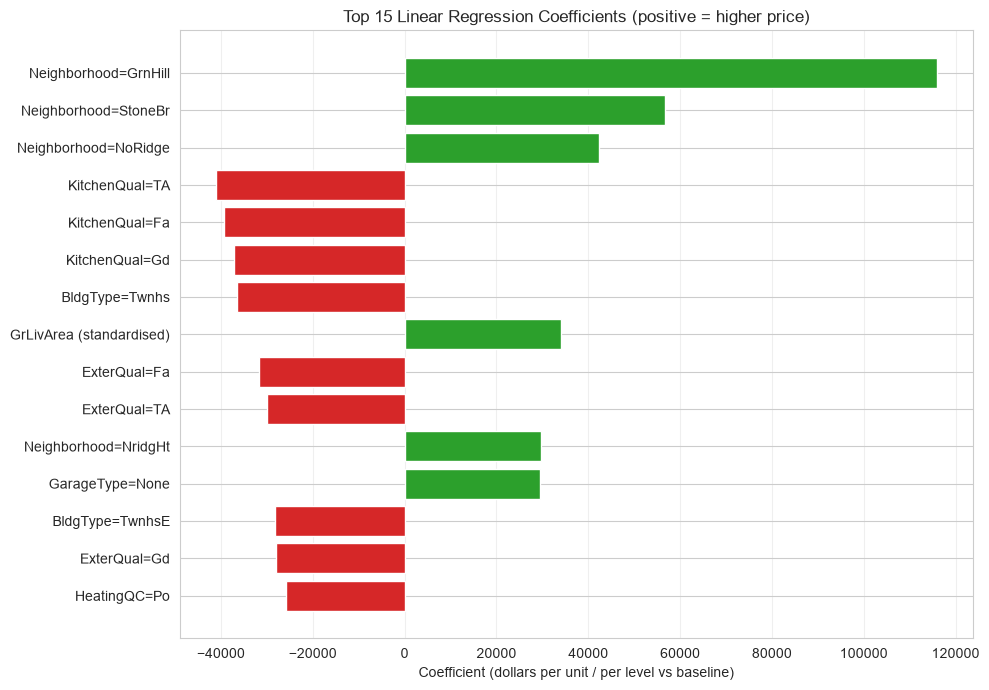

In [12]:

# Plot the top coefficients for a quick read.
top = coefficients.head(15).iloc[::-1]
colors = ["#2ca02c" if c > 0 else "#d62728" for c in top["coefficient"]]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["feature"], top["coefficient"], color=colors)
ax.set_title("Top 15 Linear Regression Coefficients (positive = higher price)")
ax.set_xlabel("Coefficient (dollars per unit / per level vs baseline)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "coefficients.png", dpi=150)
plt.show()


**Observation — what the coefficients say:**

- **Location is the single biggest lever.** `Neighborhood=GrnHill` carries a coefficient of **+115,985.78** — by far the largest in the model — followed by `StoneBr` (**+56,675.11**) and `NoRidge` (**+42,300.82**), all measured against the baseline neighbourhood `Blmngtn`. This is the price of *where* a house is, and it is why `Neighborhood` earns its place in the feature set. Note these are differences *relative to the baseline neighbourhood*, not absolute prices.
- **`GrLivArea` is the largest numeric coefficient at +34,004.83** per standard deviation — about 505 extra square feet of above-ground living space. It sits behind the location effects, which is itself a finding: in this market, *where* a house is beats *how big* it is.
- **Condition levels are large and mostly negative — and that is exactly what the baseline implies.** The baselines are `Ex` (Excellent) for `KitchenQual` and `ExterQual` and `HeatingQC`, so **every other level is a discount from Excellent**: `KitchenQual=TA` is **−41,134.42**, `ExterQual=Fa` is **−31,633.66**, `HeatingQC=Po` is **−25,921.71**. The negative signs do not mean "bad", they mean "cheaper than the top grade".
- **`BldgType` shows the same pattern.** With `1Fam` (single-family) as the baseline, `Twnhs` is **−36,456.27** and `Duplex` is **−18,999.35** — townhouses and duplexes sell for less than single-family homes, holding everything else constant.
- **One coefficient deserves a flag: `GarageType=None` is +29,472.08.** The baseline for `GarageType` is `2Types` (the alphabetically first level, held by only 23 houses), so this is a comparison against a very unusual category rather than against attached garages. Read it as *"houses with no garage differ from houses with a two-type garage"*, not as *"no garage is a premium"*. The `drop="first"` baseline is a mechanical choice, and for `GarageType` it is not a very natural reference category.
- **The caveats from step 11 apply to every number in this table.** These are associations measured on this sample of 2,930 houses, with credit shared among correlated features, and they should not be read as causal effects of, say, building a basement.

## 12. Bonus — Linear Regression vs Ridge vs Lasso


Ridge and Lasso are the same linear model with a penalty on the size of the coefficients:

- **Ridge** (L2 penalty) shrinks coefficients towards zero but never sets them exactly to zero. It helps most when there are many
  correlated features.
- **Lasso** (L1 penalty) can set coefficients exactly to zero, so it performs feature selection as a side effect.

Both are compared here using the **same leakage-safe pipeline** and evaluated on the **same held-out test set**. The penalty
strength `alpha` is chosen by **cross-validation inside the training set only** (`cv=5`), so the test set stays untouched until the
final evaluation. The regularised models are fitted on the same preprocessed matrix, so their coefficients are directly comparable
with the unpenalised model.

**A caveat on comparing coefficients across these models:** the numerical features are standardised but the one-hot dummies are
not, so the L1/L2 penalty falls unequally on the two types of feature. The comparison is therefore made on **predictive
performance**, which is unaffected by this, and not on individual coefficient magnitudes.


Model comparison on the SAME held-out test set (586 houses):
                                MSE        RMSE      R2         MAE
Model                                                              
Linear Regression      1.054886e+09  32479.0056  0.8684  19045.3907
Ridge (alpha=1.0000)   1.055475e+09  32488.0756  0.8684  18986.2924
Lasso (alpha=10.0000)  1.057224e+09  32514.9873  0.8681  19001.6365

Lasso zeroed out 5 of 68 coefficients
Ridge zeroed out 0 of 68 coefficients


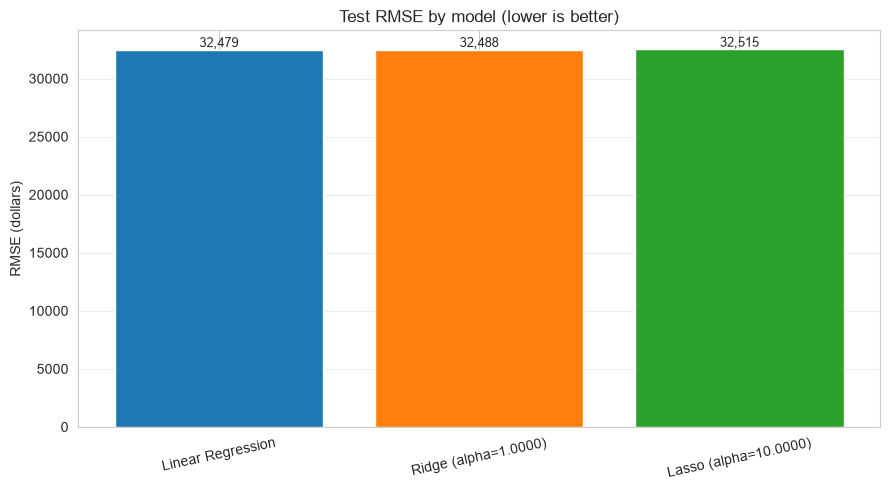

In [13]:

from sklearn.linear_model import Ridge, Lasso, RidgeCV, LassoCV

alphas = np.logspace(-3, 3, 25)

ridge_model = RidgeCV(alphas=alphas, cv=5)
ridge_model.fit(X_train_processed, y_train)

lasso_model = LassoCV(alphas=alphas, cv=5, max_iter=20000)
lasso_model.fit(X_train_processed, y_train)

models = {
    "Linear Regression": model,
    f"Ridge (alpha={ridge_model.alpha_:.4f})": ridge_model,
    f"Lasso (alpha={lasso_model.alpha_:.4f})": lasso_model,
}

rows = []
for name, m in models.items():
    pred = m.predict(X_test_processed)
    rows.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(4)
print("Model comparison on the SAME held-out test set (586 houses):")
print(comparison.to_string())

print("\nLasso zeroed out",
      int((lasso_model.coef_ == 0).sum()), "of", len(lasso_model.coef_), "coefficients")
print("Ridge zeroed out",
      int((ridge_model.coef_ == 0).sum()), "of", len(ridge_model.coef_), "coefficients")

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(comparison.index, comparison["RMSE"], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
ax.set_title("Test RMSE by model (lower is better)")
ax.set_ylabel("RMSE (dollars)")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.3)
for bar, val in zip(bars, comparison["RMSE"].values):
    ax.text(bar.get_x() + bar.get_width() / 2, val, f"{val:,.0f}",
            ha="center", va="bottom", fontsize=9)
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "model_comparison.png", dpi=150)
plt.show()


**Observation — regularisation comparison:** the table above compares all three models on the identical held-out test set of 586 houses.

- **The three models are essentially tied.** Test RMSE is 32,479.01 (Linear Regression), 32,488.08 (Ridge) and 32,514.99 (Lasso) — a spread of only **36 dollars, about 0.1%**. R² agrees to three decimals (0.8684 / 0.8684 / 0.8681). This is the expected outcome for a model with **20 features and 2,344 training rows**: there is not enough overfitting for a penalty to fix, which the tiny train/test R² gap in step 8 confirms (test 0.8684 vs train 0.8628 — the test score is in fact marginally *higher*, so there is no overfitting to correct).
- **Lasso selected `alpha = 10.0`** from the grid, which is a *real* penalty rather than a token one, and it zeroed out **5 of 68** coefficients — a genuine, if small, feature-selection effect. The 63 coefficients it kept are enough to hold predictive accuracy essentially unchanged (RMSE 32,514.99 vs 32,479.01). Lasso becomes a much more useful automatic feature selector when there are far more features than rows, which is not the situation here.
- **Ridge selected `alpha = 1.0`** and zeroed **0 of 68** coefficients, which is exactly the expected behaviour of an L2 penalty: it shrinks coefficients towards zero but never sets any exactly to zero.
- **Ridge is the best of the three on MAE** (18,986.29, against 19,045.39 for Linear Regression and 19,001.64 for Lasso) even though it is *not* the best on RMSE. MAE is the more robust metric here because it is less dominated by the handful of expensive houses, so the tiny MAE edge is the more trustworthy of the two.
- **The honest conclusion:** for this dataset, the choice among these three linear models barely matters. If the goal were prediction accuracy on *this* problem, the effort is better spent on the **model form** — a log-transformed target to fix the right-skewed errors, or a non-linear learner to capture the curvature the residuals reveal — rather than on the choice of regulariser.

## 13. Save outputs

In [14]:

processed = root / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)

# Model predictions for the test set, for inspection or downstream use.
predictions = pd.DataFrame({
    "actual_SalePrice": y_test.values,
    "predicted_SalePrice": y_pred,
    "residual": residuals,
}).sort_values("actual_SalePrice", ascending=False)
pred_csv = processed / "test_set_predictions.csv"
predictions.to_csv(pred_csv, index=False)
print("Saved test-set predictions:", pred_csv)
print(predictions.head(5).round(2).to_string(index=False))

# The full coefficient table.
coef_csv = processed / "model_coefficients.csv"
coefficients.round(4).to_csv(coef_csv, index=False)
print("\nSaved coefficient table:", coef_csv)

print("\nAll figures in", root / "outputs" / "figures")
for p in sorted((root / "outputs" / "figures").glob("*.png")):
    print(f"  {p.name}  ({p.stat().st_size / 1024:.0f} KB)")


Saved test-set predictions: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-HousePricePrediction\data\processed\test_set_predictions.csv
 actual_SalePrice  predicted_SalePrice  residual
           625000            436507.38 188492.62
           611657            396412.59 215244.41
           610000            436792.76 173207.24
           582933            406281.99 176651.01
           555000            423786.51 131213.49

Saved coefficient table: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-HousePricePrediction\data\processed\model_coefficients.csv

All figures in C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-HousePricePrediction\outputs\figures
  actual_vs_predicted.png  (108 KB)
  coefficients.png  (75 KB)
  correlation_heatmap.png  (221 KB)
  model_comparison.png  (40 KB)
  residuals.png  (167 KB)
  target_distribution.png  (45 KB)


---

## Summary
- Loaded the Ames Housing dataset (2,930 houses × 82 fields) with `NA` strings parsed as missing
- Inspected shape, types, nulls, descriptive statistics and the right-skewed target distribution
- Selected 11 numeric and 9 categorical features with a documented reason for each
- Handled missing values by pipeline (median for numeric, `None` label for missing garages, most-frequent for categorical)
- Plotted a correlation heatmap and discussed multicollinearity between the area features
- Built a `ColumnTransformer` + `Pipeline` so imputation and encoding are fitted on training data only — no leakage
- Split 80/20 with `random_state=42`, trained `LinearRegression`, and evaluated with **MSE, RMSE and R²**
- Plotted actual vs predicted with a reference diagonal, and a three-panel residual analysis
- Analysed coefficients with the scaling, the one-hot baseline categories and the multicollinearity caveat stated
- Bonus: compared against Ridge and Lasso with CV-selected alphas on the same held-out test set